# Case Study 4: Predicting Student Dropout and Academic Success

## Introduction
This case study analyzes student data to understand academic outcomes and predict whether a student will Dropout, remain Enrolled, or Graduate. Pandas and NumPy are used for data analysis, Matplotlib and Seaborn for visualization, and Scikit-learn for classification.

## Objectives
- Understand and clean the dataset.
- Perform exploratory data analysis.
- Apply hypothesis testing to first-semester grades.
- Build a multiclass logistic regression model.
- Evaluate the model and interpret its results.

In [1]:
import pandas as pd
import numpy as np

## A. Data Understanding and Preprocessing

In this section, the dataset is loaded into a Pandas DataFrame. The data structure, number of records, column types, missing values, duplicate records, and target categories are examined to understand the dataset before analysis.

In [2]:
df=pd.read_csv("Studentdata.csv",sep=";")

In [3]:
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [4]:
df.shape

(4424, 37)

In [5]:
df.dtypes

Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance\t                        int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Admission grade                                   float64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender        

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

In [7]:
df.isnull().sum()

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [8]:
df.nunique()

Marital status                                      6
Application mode                                   18
Application order                                   8
Course                                             17
Daytime/evening attendance\t                        2
Previous qualification                             17
Previous qualification (grade)                    101
Nacionality                                        21
Mother's qualification                             29
Father's qualification                             34
Mother's occupation                                32
Father's occupation                                46
Admission grade                                   620
Displaced                                           2
Educational special needs                           2
Debtor                                              2
Tuition fees up to date                             2
Gender                                              2
Scholarship holder          

In [9]:
df.columns

Index(['Marital status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance\t', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd

In [10]:
print(df["Target"].value_counts())
print(df["Target"].value_counts(normalize=True).mul(100).round(2))

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


### Data Cleaning

Some column names are renamed to remove unwanted spaces and special characters. This makes the column names easier to use in Python code. Missing values and duplicate records are checked before proceeding.

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df=df.rename(columns={'Daytime/evening attendance\t':'Daytime/evening attendance',"Mother's qualification":'Mother_s qualification',
                    "Father's qualification":'Father_s qualification',"Mother's occupation":'Mother_s occupation', 
                    "Father's occupation":'Father_s occupation'})

In [13]:
print("Target Variable : Target")
print(df['Target'].value_counts())
predictors=['Marital status',
 'Application mode',
 'Application order',
 'Course',
 'Daytime/evening attendance',
 'Previous qualification',
 'Previous qualification (grade)',
 'Nacionality',
 'Mother_s qualification',
 'Father_s qualification',
 'Mother_s occupation',
 'Father_s occupation',
 'Admission grade',
 'Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'Age at enrollment',
 'International',
 'Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)',
 'Unemployment rate',
 'Inflation rate',
 'GDP']
print("Predictors:",predictors)

Target Variable : Target
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Predictors: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', 'Mother_s qualification', 'Father_s qualification', 'Mother_s occupation', 'Father_s occupation', 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)'

In [14]:
df.columns.tolist()

['Marital status',
 'Application mode',
 'Application order',
 'Course',
 'Daytime/evening attendance',
 'Previous qualification',
 'Previous qualification (grade)',
 'Nacionality',
 'Mother_s qualification',
 'Father_s qualification',
 'Mother_s occupation',
 'Father_s occupation',
 'Admission grade',
 'Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'Age at enrollment',
 'International',
 'Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)',
 'Unemployment rate',
 'Inflation rat

### Classification of Attributes

The dataset attributes are grouped into numerical, binary, and categorical variables. Numerical variables represent measurable quantities, binary variables have two possible categories, and categorical variables represent groups or labels. Descriptive statistics are used to understand the numerical variables.

In [15]:
numerical=[
'Previous qualification (grade)','Age at enrollment',
 'Admission grade','Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)',
 'Unemployment rate',
 'Inflation rate',
 'GDP']
df[numerical].nunique()

Previous qualification (grade)                    101
Age at enrollment                                  46
Admission grade                                   620
Curricular units 1st sem (credited)                21
Curricular units 1st sem (enrolled)                23
Curricular units 1st sem (evaluations)             35
Curricular units 1st sem (approved)                23
Curricular units 1st sem (grade)                  805
Curricular units 1st sem (without evaluations)     11
Curricular units 2nd sem (credited)                19
Curricular units 2nd sem (enrolled)                22
Curricular units 2nd sem (evaluations)             30
Curricular units 2nd sem (approved)                20
Curricular units 2nd sem (grade)                  786
Curricular units 2nd sem (without evaluations)     10
Unemployment rate                                  10
Inflation rate                                      9
GDP                                                10
dtype: int64

In [16]:
binary=['Daytime/evening attendance','Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder','International']
df[binary].nunique()

Daytime/evening attendance    2
Displaced                     2
Educational special needs     2
Debtor                        2
Tuition fees up to date       2
Gender                        2
Scholarship holder            2
International                 2
dtype: int64

In [17]:
catogerical=['Marital status',
 'Application mode',
 'Application order',
 'Course','Previous qualification',
 'Nacionality',
 'Mother_s qualification',
 'Father_s qualification',
 'Mother_s occupation', 'Father_s occupation']
df[catogerical].nunique()

Marital status             6
Application mode          18
Application order          8
Course                    17
Previous qualification    17
Nacionality               21
Mother_s qualification    29
Father_s qualification    34
Mother_s occupation       32
Father_s occupation       46
dtype: int64

In [18]:
df[numerical].describe()

,Previous qualification (grade),Age at enrollment,Admission grade,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,132.613314,23.265145,126.978119,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,13.188332,7.587816,14.482001,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,95.000000,17.000000,95.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,125.000000,19.000000,117.900000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,133.100000,20.000000,126.100000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,140.000000,25.000000,134.800000,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,190.000000,70.000000,190.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


### Outlier Detection

The Interquartile Range (IQR) method is used to identify possible outliers in numerical attributes. Values outside the lower and upper IQR limits are flagged for investigation. These values are not automatically removed because they may represent genuine student records.

In [19]:
for col in numerical :
    q1=df[col].quantile(0.25)
    q3=df[col].quantile(0.75)
    iqr=q3-q1
    o=df[(df[col]<q1-1.5*iqr) |
                  (df[col]>q3+1.5*iqr)]
    print(col,":",len(o),"Possible outlier")

Previous qualification (grade) : 179 Possible outlier
Age at enrollment : 441 Possible outlier
Admission grade : 86 Possible outlier
Curricular units 1st sem (credited) : 577 Possible outlier
Curricular units 1st sem (enrolled) : 424 Possible outlier
Curricular units 1st sem (evaluations) : 158 Possible outlier
Curricular units 1st sem (approved) : 180 Possible outlier
Curricular units 1st sem (grade) : 726 Possible outlier
Curricular units 1st sem (without evaluations) : 294 Possible outlier
Curricular units 2nd sem (credited) : 530 Possible outlier
Curricular units 2nd sem (enrolled) : 369 Possible outlier
Curricular units 2nd sem (evaluations) : 109 Possible outlier
Curricular units 2nd sem (approved) : 44 Possible outlier
Curricular units 2nd sem (grade) : 877 Possible outlier
Curricular units 2nd sem (without evaluations) : 282 Possible outlier
Unemployment rate : 0 Possible outlier
Inflation rate : 0 Possible outlier
GDP : 0 Possible outlier


## B. Exploratory Data Analysis

Exploratory data analysis is performed to understand student characteristics and the distribution of academic outcomes. Histograms, bar charts, and box plots are used to identify patterns in age, admission grades, first-semester grades, and student outcomes.

In [20]:
import matplotlib.pyplot as plt 

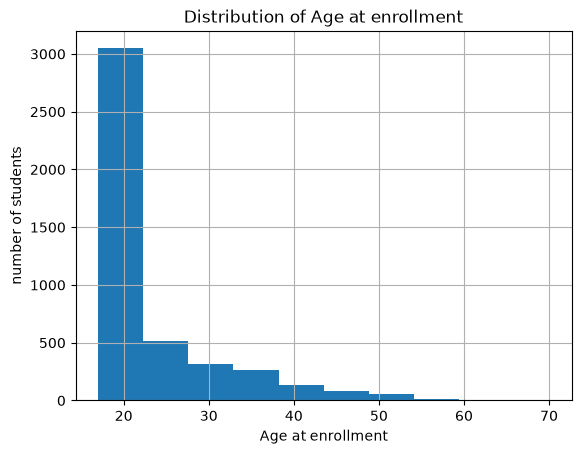

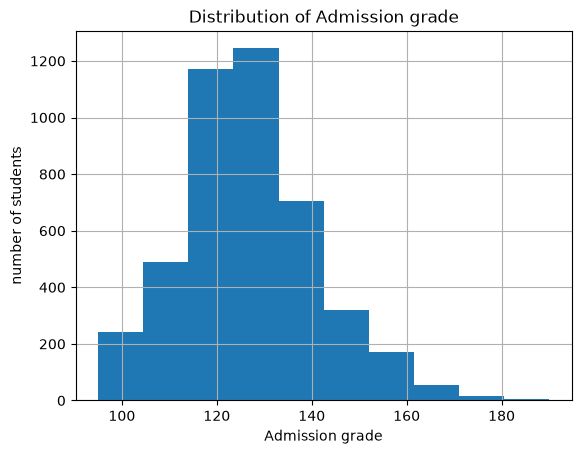

In [21]:
s=['Age at enrollment',
 'Admission grade']
for col in s :
    df[col].hist()
    plt.title("Distribution of "+ col)
    plt.xlabel(col)
    plt.ylabel("number of students")
    plt.show()

### Distribution of Student Outcomes

The charts show the number and percentage of students in the Dropout, Enrolled, and Graduate categories. Comparing these categories helps identify class imbalance in the dataset.

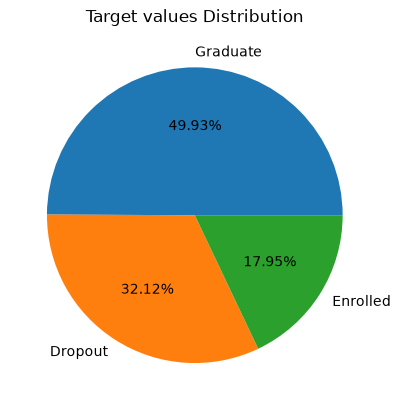

In [22]:
df["Target"].value_counts().plot(kind="pie",autopct="%1.2f%%")
plt.title("Target values Distribution")
plt.ylabel("")
plt.show()

In [23]:
df["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

In [24]:
df[numerical].describe()

,Previous qualification (grade),Age at enrollment,Admission grade,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,132.613314,23.265145,126.978119,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,13.188332,7.587816,14.482001,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,95.000000,17.000000,95.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,125.000000,19.000000,117.900000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,133.100000,20.000000,126.100000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,140.000000,25.000000,134.800000,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,190.000000,70.000000,190.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


### Comparison of Student Characteristics

Box plots are used to compare admission grades, first-semester grades, and age at enrollment across the three outcome groups. The plots show differences in medians, distributions, and possible outliers. These patterns indicate associations and do not prove causation.

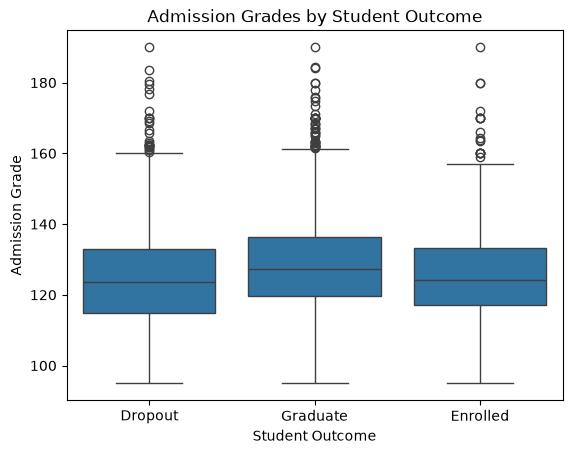

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(x=df['Target'], y=df['Admission grade'])
plt.title('Admission Grades by Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('Admission Grade')
plt.show()

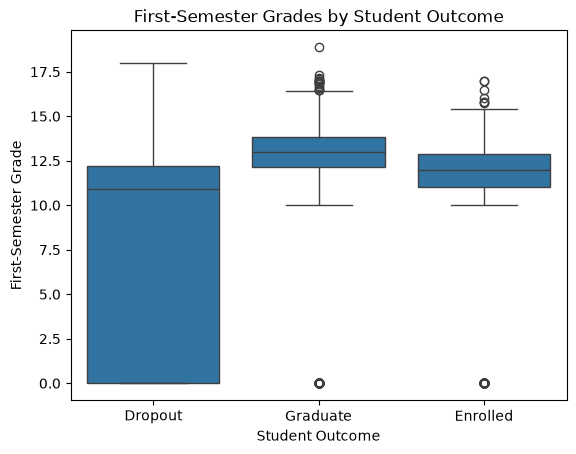

In [26]:
sns.boxplot(x=df['Target'],y=df['Curricular units 1st sem (grade)'])
plt.title('First-Semester Grades by Student Outcome')
plt.xlabel('Student Outcome')
plt.ylabel('First-Semester Grade')
plt.show()

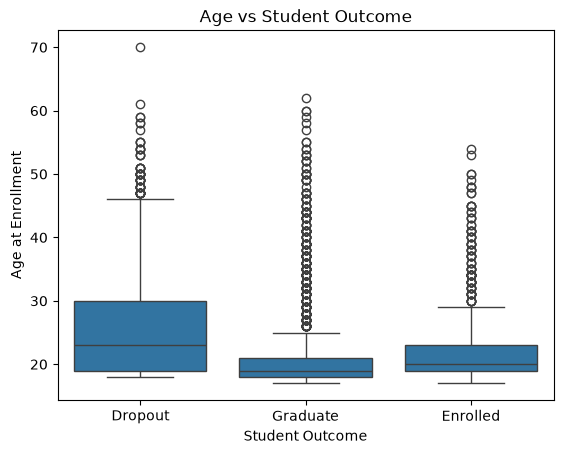

In [27]:
sns.boxplot(data=df, x='Target', y='Age at enrollment')
plt.title('Age vs Student Outcome')
plt.xlabel("Student Outcome")
plt.ylabel("Age at Enrollment")
plt.show()

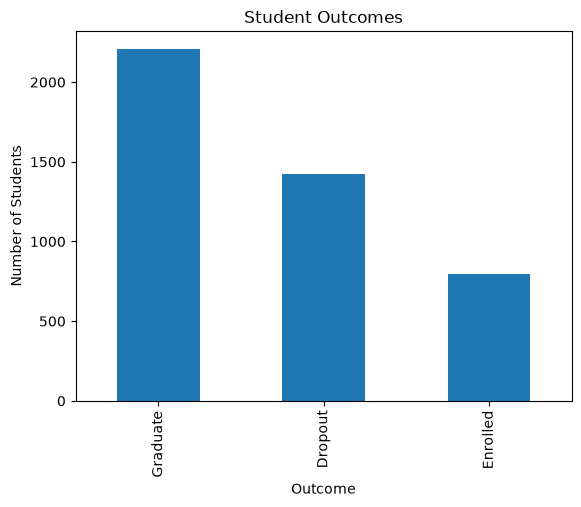

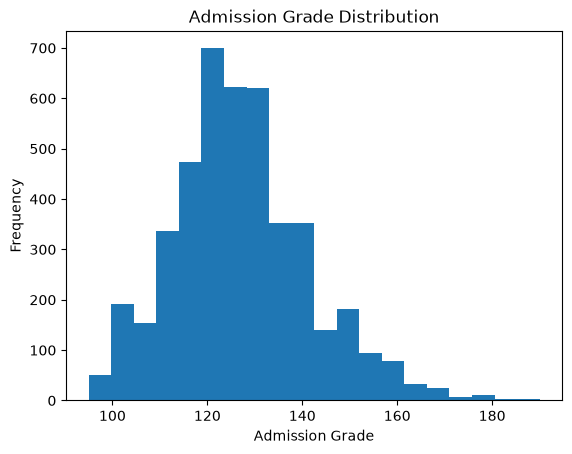

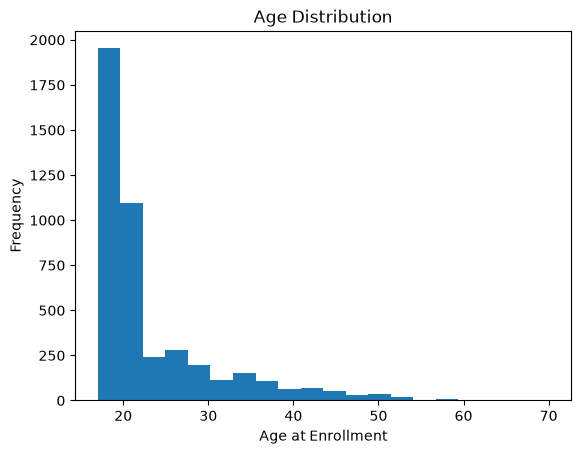

In [28]:

# 1. Bar chart
df["Target"].value_counts().plot(kind="bar")
plt.title("Student Outcomes")
plt.xlabel("Outcome")
plt.ylabel("Number of Students")
plt.show()

# 2. Histogram of admission grades
df["Admission grade"].plot(kind="hist", bins=20)
plt.title("Admission Grade Distribution")
plt.xlabel("Admission Grade")
plt.ylabel("Frequency")
plt.show()

# 3. Histogram of student ages
df["Age at enrollment"].plot(kind="hist", bins=20)
plt.title("Age Distribution")
plt.xlabel("Age at Enrollment")
plt.ylabel("Frequency")
plt.show()

## C. Hypothesis Testing

The purpose of hypothesis testing is to determine whether first-semester grades differ among Dropout, Enrolled, and Graduate students.

**Null hypothesis (H₀):** The mean first-semester grades are equal across all three outcome groups.

**Alternative hypothesis (H₁):** At least one group has a different mean first-semester grade.

The significance level is 0.05. If the p-value is below 0.05, the null hypothesis is rejected. Otherwise, there is insufficient evidence to reject it.

In [29]:
print("H0: Mean grades are equal across all student outcomes.")
print("H1: At least one group has a different mean grade.")

H0: Mean grades are equal across all student outcomes.
H1: At least one group has a different mean grade.


In [30]:
print("Selected Test: One-Way ANOVA")
print("Significance Level: 0.05")
print("Reason: Compare first-semester grades across three outcomes.")

Selected Test: One-Way ANOVA
Significance Level: 0.05
Reason: Compare first-semester grades across three outcomes.


### Interpretation of Hypothesis Test

The F-statistic and p-value are used to assess whether the group means differ statistically. A significant result indicates that at least one group mean differs, but further testing is needed to determine which groups differ. Statistical significance does not necessarily imply practical importance.

In [31]:
import pandas as pd
from statsmodels.stats.oneway import anova_oneway

col = "Curricular units 1st sem (grade)"
groups = [df[df["Target"] == g][col].dropna()
          for g in ["Dropout", "Enrolled", "Graduate"]]

result = anova_oneway(groups)

print("F-statistic:", round(result.statistic, 2))
print("P-value:", result.pvalue)

if result.pvalue < 0.05:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

F-statistic: 522.43
P-value: 9.605709173998977e-179
Reject the null hypothesis


## D. Student Outcome Classification

A multiclass logistic regression model is developed to predict Dropout, Enrolled, and Graduate outcomes. Selected student characteristics are used as input features. The dataset is divided into training and testing sets, and the model is trained on the training data before making predictions on the test data.

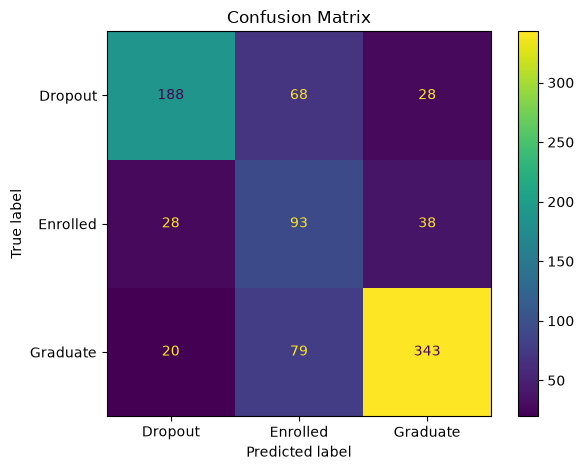

In [32]:
# Part D: Logistic Regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay,precision_score,recall_score,f1_score)

# picking the columns I want to use as inputs
features=["Admission grade","Previous qualification (grade)",
          "Age at enrollment","Application mode",
          "Application order","Course",
          "Previous qualification","Scholarship holder",
          "Tuition fees up to date","Debtor","Gender",
          "Displaced","Curricular units 1st sem (approved)",
          "Curricular units 1st sem (grade)","Curricular units 1st sem (evaluations)",
          "Curricular units 1st sem (credited)","Curricular units 1st sem (enrolled)"]

X=df[features]
y=df["Target"]


X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# separating numeric and categorical columns, since they need different preprocessing

num_cols=["Admission grade",
          "Previous qualification (grade)",
          "Age at enrollment","Curricular units 1st sem (approved)",
          "Curricular units 1st sem (grade)","Curricular units 1st sem (evaluations)",
          "Curricular units 1st sem (credited)","Curricular units 1st sem (enrolled)"]

cat_cols=[c for c in features if c not in num_cols]

# scaling the numeric columns
# fit only on train so no info leaks from the test set
scaler=StandardScaler()
X_train_num=scaler.fit_transform(X_train[num_cols])
X_test_num=scaler.transform(X_test[num_cols])

# one-hot encoding the categorical columns
encoder=OneHotEncoder(handle_unknown="ignore")
X_train_cat=encoder.fit_transform(X_train[cat_cols]).toarray()
X_test_cat=encoder.transform(X_test[cat_cols]).toarray()

# putting the numeric and categorical parts back together
X_train_final=np.concatenate((X_train_num,X_train_cat),axis=1)
X_test_final=np.concatenate((X_test_num,X_test_cat),axis=1)

# training the logistic regression
# class_weight="balanced" because the classes are not evenly distributed
model=LogisticRegression(max_iter=2000,class_weight="balanced")
model.fit(X_train_final,y_train)

# making predictions on the test set
y_pred=model.predict(X_test_final)

# confusion matrix to see where the model gets confused
labels=["Dropout","Enrolled","Graduate"]
cm=confusion_matrix(y_test,y_pred,labels=labels)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=labels)
disp.plot()
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


### Model Evaluation

The model is evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. These measures help assess overall performance and identify which outcome categories are predicted more or less accurately. Macro-averaged metrics give equal weight to each class.

In [33]:

# evaluating the model
print("Accuracy:",round(accuracy_score(y_test,y_pred),3))
print("\nClassification Report:")
print(classification_report(y_test,y_pred))

# macro averages treat each class equally
print("Macro Precision:",round(precision_score(y_test,y_pred,average="macro"),3))
print("Macro Recall:",round(recall_score(y_test,y_pred,average="macro"),3))
print("Macro F1-score:",round(f1_score(y_test,y_pred,average="macro"),3))


Accuracy: 0.705

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.80      0.66      0.72       284
    Enrolled       0.39      0.58      0.47       159
    Graduate       0.84      0.78      0.81       442

    accuracy                           0.71       885
   macro avg       0.67      0.67      0.67       885
weighted avg       0.74      0.71      0.72       885

Macro Precision: 0.674
Macro Recall: 0.674
Macro F1-score: 0.665


### Interpretation of Logistic Regression Coefficients

The model coefficients indicate how input features are associated with each outcome in the fitted logistic regression model. Positive and negative coefficients indicate the direction of association relative to the model's class-specific decision function. Coefficients do not establish causation, and their interpretation depends on feature encoding and scaling.

In [34]:
# Part D.5: Model interpretation
import pandas as pd

# get feature names
num_names = list(num_cols)
cat_names = list(encoder.get_feature_names_out(cat_cols))
all_names = num_names + cat_names

# loop through each outcome and show top 10 coefficients
for i in range(3):
    print("\nOutcome:", model.classes_[i])
    coef = model.coef_[i]
    result = pd.DataFrame({"Feature": all_names, "Coefficient": coef})
    result["Absolute Value"] = abs(result["Coefficient"])
    result = result.sort_values("Absolute Value", ascending=False)
    print(result.head(10))


Outcome: Dropout
                                Feature  Coefficient  Absolute Value
3   Curricular units 1st sem (approved)    -1.666860        1.666860
13                  Application mode_15    -1.499529        1.499529
70            Tuition fees up to date_0     0.980113        0.980113
35                           Course_171    -0.879632        0.879632
49                          Course_9853     0.823246        0.823246
52             Previous qualification_2     0.809860        0.809860
7   Curricular units 1st sem (enrolled)     0.806954        0.806954
71            Tuition fees up to date_1    -0.783957        0.783957
59            Previous qualification_12    -0.653102        0.653102
20                  Application mode_42     0.624778        0.624778

Outcome: Enrolled
                      Feature  Coefficient  Absolute Value
40                Course_9119     1.040982        1.040982
12        Application mode_10    -0.897147        0.897147
10         Application mode

## E. Conclusion

This case study uses data preprocessing, exploratory data analysis, hypothesis testing, and logistic regression to investigate student academic outcomes. The evaluation metrics help identify the strengths and weaknesses of the model. The results may support student guidance and academic assistance, but predictions should be validated and used responsibly.